# **Capitulo 1: Optimizadores**

En estos notebook ire trabajando cosas de los capitulos que me hayan llamado la atencion o que considere importantes. No necesariamente tratare el contenido total del capitulo. 
En este caso el grueso del notebook tratara sobre los algoritmos de optimizacion de descenso gradiente.

# Batch Gradient Descent
Es un tema que ya habia tratado en clase de optimizacion de tercero de matematicas.La idea es realmente intuitiva y no la tratare en profunidad.  
Partimos de una funcion f diferenciable que queramos minimizar y un punto inicial θ0. A partir de hay calculamos el gradiente de la funcion en ese punto y actualizamos y definimos θ1 := θ0 - Df(θ0). El signo menos es porque el gradiente nos da la direccion de maximo crecimiento. Tambien podemos añadir un factor c multiplicando a Df si queremos aumentar o disminuir el tamaño de paso que se da en cada iteracion. Una opcion seria primero calcular el gradiente y luego optimizar por separado g(c)= θ0 - c*Df(θ0) para elegir el tamaño de paso mas adecuado en cada iteracion. El algortimo converge siempre aunque si la funcion f no es convexa puede converger a un minimo local y no al global, dependerá del punto de partida.  
En el contexto de usar este algoritmo para problemas de regresion lineal se debe tener en cuenta que la funcion de perdida f en general dependera de todo el dataset y en cada iteracion se debera evaluar un gradiente que sera una funcion que dependa de todo el dataset. Esto puede ser un poco lento si tenemos muchos datos y poco practico si tenemos un dataset que aumente con el tiempo ya que si agregamos un dato nuevo deberemos correr todo el algoritmo sobre todos los datos por completo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import autograd.numpy as anp
from autograd import grad

In [2]:
def gradient_descent (f, Df, x0, alfa=0.1, itmax=200, tol=1e-3):
    '''
    Funcion bach_gradient_descent
    Implementa el algoritmo de descenso de gradiente tradicional usando la funcion determinada por todo el dataset
    Parametros:
       - Df: Funcion gradiente de f donde f es la funcion objetivo. Viene en forma de array de funciones. ∇f:Rn→Rn
       - x0: Punto de inicio para el algoritmo. Es un vector de numpy.
       - itmax: numero maximo de iteraciones. Es un entero de python.
       - alfa: Tamaño y direccion de paso (Learing Rate).
       - tol: Tolerancia. Cuando la norma del gradiente sea suficientemente cercana a 0 paramos el algoritmo.
    '''
    x = np.array(x0, dtype=float).copy() #partimos del dato inical

    for i in range(itmax):
        Dfx= Df(x)
        #Dfx = np.array([f(x) for f in Df])
        #si el gradiente es cercano a cero estamos cerca de un extremo y paramos
        if np.linalg.norm(Dfx)<tol:
            break
        x_next = x - alfa*Dfx
        x = x_next
    return x

In [3]:
f = lambda x: x[0]**2
Df = grad(f)
x0 = np.array([1.0])
itmax = 50

gradient_descent(f, Df, x0, 1, itmax=itmax); #output: 1
gradient_descent(f, Df, x0, 1/2, itmax=itmax); #output: 0

Vemos que si ponemos un tamaño de paso de 1 el algoritmo se queda oscilando entre los valores 1 y -1 y nunca llega a acercarse al optimo. Esto es un problema de este algoritmo, si reducimos el tamaño de paso mejoramos este comportamiento como vemos en el otro ejemplo.

In [4]:
f = lambda x: x[0]**2 + x[1]**2
Df = grad(f)
x0 = np.array([1, 1])
itmax = 50

gradient_descent(f, Df, x0, 1, itmax=itmax); #output: [1, 1]
gradient_descent(f, Df, x0, 1/2, itmax=itmax); #output: [0, 0]

Vemos que en este caso pasa lo mismo por el mismo motivo

## Adaptación del tamaño de paso  
Podemos ir probando tamaños de paso hasta que uno nos de un resultado suficientemente bueno aunque esto puede resultar poco practico en ejemplos reales. Por eso utilizaremos un algortimo de optimizacion 1D para escoger el alfa que minice f(x - alfa*Dfx).  
Existen varios algoritmos como el de la biseccion, el de Newton, Fibonacci, secion aurea ... Todos estos metodos los he estudiado e implementado en la asignatura de optimizacion por lo que ente caso usare otro metodo, el método de Backtracking Line Search:

### Método de **Backtracking Line Search**
Desarrollaremos la fundamentacion matematica de este procedimiento.  
Tenemos la funcion f(x−α∇f(x)) que buscamos minimizar variando α. Partiremos de un alfa grande alfa=1 y lo hiremos disminuyendo segun un factor tau hasta que f(x−α∇f(x)) sea suficientemente pequeño. Ese suficientemente pequeño vendra dado por la **condicion de Armijo-Goldstein** 

Partimos de g(α) = f(x−α∇f(x)) por lo tanto g'(α) = ∇f(x−α∇f(x)) * -∇f(x) aplicando la regla de la cadena.  
Ahora hacemos el desarrollo de Taylor de g centrado en α=0:  
$$
g(\alpha) = f(x) - \alpha \, \|\nabla f(x)\|^2
$$
Por lo tanto α || ∇f(x)|| ^2 nos esta diciendo cuanto podemos esperar que disminuya la funcion si no movemos un paso alfa. multiplicaremos esta cantidad por un factor 0<c<1 y definiremos la condicion de parada como la condicion de Armijo-Goldstein que es:  
$$
f(x−\alpha \nabla f(x)) \leq f(x) - c\alpha \|\nabla f(x)\|^2
$$


In [5]:
def backtracking_line_search(f, Df, x0, tau=0.5, c=1e-4, itmax=200, tol=1e-3):
    x = np.array(x0, dtype=float).copy()
    for i in range(itmax):
        alfa = 1
        Dfx = Df(x)
        #si el gradiente es cercano a cero estamos cerca de un extremo y paramos
        if np.linalg.norm(Dfx)<tol:
            break
        for j in range(itmax):
            if f(x-alfa*Dfx) <= f(x)-c*alfa*np.linalg.norm(Dfx)**2:
                break
            alfa = tau*alfa
        x_next = x - alfa*Dfx
        x=x_next
    return x

In [6]:
f = lambda x: x[0]**2 + x[1]**2
Df = grad(f)
x0 = np.array([1, 1])
itmax = 50

backtracking_line_search(f, Df, x0, itmax=itmax); #output: [0, 0]

Vemos que en este caso antes habia algunos alfa que producian que el algoritmo se quedase oscilando y teniamos que seleccionar el alfa a mano hasta que funcionase. Sin embargo usando este metodo para optimizar el tamaño de paso este problema se soluciona. Sin embargo este metodo puede ser aun poco eficiente para problemas de ML con datasets grandes porque **requiere muchas evaluaciones de una funcion que es excesivamente grande si el dataset es grande**. Por tanto implmentaremos mas metodos para adaptar el tamaño de paso. A continuacion implmentaremos el metodo de Root Mean Squared Propagation (RMSProp).

### Metodo de **Root Mean Squared Propagation (RMSProp)**

El metodo RMSProp es una evolucion del metodo Adagrad que consiste en ir guardando la media de gradientes acumulados y usarlo al momento de actualizar el valor de los parametros. El problema que presenta adagrad es que a medida que se van acumulando los gradientes el valor del gradiente actual va perdiendo importancia ya que cada vez es una porcion mas pequeña del total y finalmente el aprendizaje se acaba parando. El metodo RMSProp soluciona este problema usando una media ponderada exponencialmente en la que la importancia de gradientes recientes es mucho mayor a la de los gradientes muy antiguos. De esta manera los gradientes nuevos porducen un cambio constante en la direccion de busqueda durante todo el entrenamiento y el aprendizaje no se para.

En nuestro modelo de descenso de gradiente bach la actualizacion de los parametros es de la forma:
$$
x_{t+1} = x_t - \alpha\, \nabla f(x)
$$
En este caso lo que nosotros controlaremos sera el tamaño de paso que tendra en cuenta la ponderacion de los gradientes previos. Nuestra actualizacion del punto x queda:
$$
x_{t+1} = x_{t} - \frac{\nu}{\sqrt{v_t + \varepsilon}} \, \nabla f(x)
$$
donde g sub x es el acumulado de los gradientes previos y nu es una contante que llamaremos constante de aprendizaje que controla la importancia de los gradientes previos. La ponderacion de los gradientes es dela forma: 
$$
v_t = \beta \, v_{t-1} + (1 - \beta) \nabla f(x) ^2
$$
Donde Beta es una constante de ponderacion. Si g subx en vez de de esta forma los calculasemos haciendo una media aritmetica de todos los gradientes entonces estariamos frente al metodo Adagrad.

In [7]:
def rmspropagation(f, Df, x0, itmax=200, tol=1e-3, nu=0.1, epsilon=1e-8, beta=0.9):
    x = np.array(x0, dtype=float).copy()
    vt = np.zeros_like(x)
    for i in range(itmax):
        Dfx = Df(x)
        if np.linalg.norm(Dfx)<tol:
            break
        vt = beta*vt +(1-beta)*Dfx**2
        alfa = nu/np.sqrt(vt+epsilon)
        #Nota: A diferencia de en backtracking aqui alfa sera un vector y no un escalar
        #Esto no genera problema en nuetro codidigo porque python hace la multiplicacion 
        #componente a componente y al dividir entre nu(escalar) o sumar epsilon (escalar)
        #python hace la operacion componente a componente considerando nu y epsilon vectores
        #contantemente su valor escalar nu=[0.001, 0.001, ..., 0.001].
        x = x - alfa*Dfx
    return x


In [8]:
f = lambda x: x[0]**2 + x[1]**2
Df = grad(f)
x0 = np.array([1, 1])
itmax = 50

rmspropagation(f, Df, x0, itmax=itmax, nu=0.1); #Output: [0.00031952, 0.00031952] (nu=0.1)
rmspropagation(f, Df, x0, itmax=itmax, nu=0.2); #Output: [0.94758416, 0.94758416] (nu=0.001)

Con estos dos ejemplos vemos que **la convergencia del algoritmo depende del learing rate nu**. En el primer ejemplo donde usamos un nu estardar para problemas de redes profundas al algoritmo avanza de manera extremadamente lenta y no converge en itmax. Sin embargo si modificamos nu para que sea 0.1 los pasos ya seran los suficientemente rapidos como para converger en el numero maximo de iteraciones. **Esta rigidez del learing rate que puede condicionar la utilidad del algoritmo por completo motiva de manera natural la implementacion de una variante de este algoritmo que modifique el learing rate de manera dinamica**. Hay varias formas de hacer esto, una podria ser usar una combinacion de rmsprop con una forma de backtracking. En este caso usaremos un metodo adaptativo propio.

### Actualizacion dinámica del learning rate para RMSProp

Empezaremos motivando el problema. Ya hemos visto que si elegimos un learing rate muy pequeño el algoritmo sera lento y necesitara de muchas iteraciones para converger. Pero ademas veremos ahora que elegir un learing rate grande tambien puede causar la no convergencia. Esto dependera unicamente de la naturaleza del problema que estemos tratando. Consideremos la funcion:
$$
f(x, y) = \sin(50x) + 0.01\,y^2
$$
Tras aplicar RMSProp vemos como nu=0.001 rinde en este caso mejor que nu=0.1.

In [9]:
f = lambda x: anp.sin(50*x[0]) + 0.01*x[1]**2
Df = grad(f)
x0 = np.array([0.1, 0.1])
itmax = 50

f(rmspropagation(f, Df, x0, itmax=itmax, nu=0.1)); #Output: 0.5313970036129955
f(rmspropagation(f, Df, x0, itmax=itmax, nu=0.001)); #Output: -0.9999754919009353 (minimo es -1)

Graficamente esta funcion se ve asi:

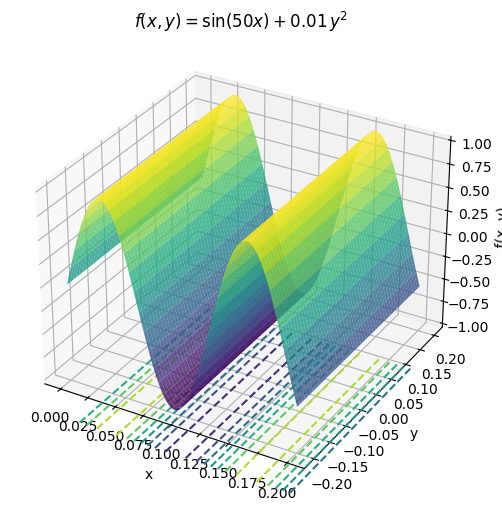

In [10]:
%matplotlib inline
# Definir la función
def f(x, y):
    return anp.sin(50*x) + 0.01*y**2

# Crear malla de puntos
x = np.linspace(0, 0.2, 400)  # intervalo cercano a x0=0.1
y = np.linspace(-0.2, 0.2, 400)
X, Y = np.meshgrid(x, y)
Z = f(X, Y)

# Crear figura 3D
fig = plt.figure(figsize=(10,6))
ax = fig.add_subplot(111, projection='3d')

# Graficar superficie
ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.8)

# Graficar contornos en el plano XY
ax.contour(X, Y, Z, zdir='z', offset=np.min(Z)-0.5, cmap='viridis', linestyles='dashed')

# Etiquetas
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f(x, y)')
ax.set_title(r'$f(x, y) = \sin(50x) + 0.01\,y^2$')

plt.show()

Esto se debe a que la funcion que tratamos ahora es mucho mas ruidosa con cambios de gradiente mas bruscos y un tamaño de paso muy grande hace que vayamos saltando de un valle a otro en vez de converger.
El comportamiento que queremos que tenga la adaptacion dinamica del paso es el siguiente:  
 (1) Si el gradiente cambia de signo en una iteracion -> Disminuimos el tamaño de paso  
 (2) Si el gradiente mantiene signo constante en una iteracion -> Aumentamos el tamaño de paso

In [11]:
def rmspropagation_adaptativo(f, Df, x0, itmax=200, tol=1e-3, nu=0.1, epsilon=1e-8, beta=0.9, nu_min=1e-6, nu_max=1, nu_fac=0.5):
    x = np.array(x0, dtype=float).copy()
    vt = np.zeros_like(x)
    nu=np.array([nu]*len(x))
    Dfxprev = vt
    for i in range(itmax):
        Dfx = Df(x)
        if np.linalg.norm(Dfx)<tol:
            break
        vt = beta*vt +(1-beta)*Dfx**2
        for j in range(len(Dfx)):
            if Dfx[j]*Dfxprev[j] <= 0:
                nu[j]=nu[j]*nu_fac
            else:
                nu[j]=nu[j]*(1+nu_fac)
        nu = np.clip(nu, nu_min, nu_max)
        alfa = nu/np.sqrt(vt+epsilon)
        x = x - alfa*Dfx
        Dfxprev = Dfx
    return x

In [12]:
f = lambda x: anp.sin(50*x[0]) + 0.01*x[1]**2
Df = grad(f)
x0 = np.array([0.1, 0.1])
itmax = 50

f(rmspropagation_adaptativo(f, Df, x0, itmax=itmax, nu=0.1)); #Output: -0.9999999999023945
f(rmspropagation_adaptativo(f, Df, x0, itmax=itmax, nu=0.001)); #Output: -0.9999854284046532

Con este nuevo metodo adapatativo vemos que el rendimiento que obtiene rmsprop con nu grande es considerablemente mejor, antes si aumentabamos el numero de iteraciones seguia dando saltos y ahora se va acercando a un minumo local. Veamos como se comporta en ele ejemplo sencillo el algoritmo si ponemos nu pequeña

In [13]:
f = lambda x: x[0]**2 + x[1]**2
Df = grad(f)
x0 = np.array([1, 1])
itmax = 50

rmspropagation_adaptativo(f, Df, x0, itmax=itmax, nu=0.1); #Output: [0.00024121 0.00024121]
rmspropagation_adaptativo(f, Df, x0, itmax=itmax, nu=0.001); #Output: [-0.00024703 -0.00024703]

Vemos que de manera analoga poner un learing rate pequeño para un problema simple no ralentiza en exceso la convergencia como antes. En definitiva hemos hecho un metodo que es poco sensible al learing rate con el que lo iniciemos. Podemos probar con muchas funciones y ver que nuestro RMSProp adaptativo funciona extremadamente bien en general. Pero fuentes sugieren que puede ser un poco mas lento en algun tipo de problemas porque carece de inercia. Una propiedad que tiene otros modelos y es util para controlar ocilaciones o acelerar el entrenamiento si la direccion del gradiente esta siendo monotona.

### Método de **Adam (Adaptative Momentum Estimation)**

El metodo Adam consiste en convinar dos metodos previos, el RMSProp y el momentum. El rmsprop lo hemos implmentado en la seccion previa. El momentum es en cierta forma similar, es de la forma:
$$
v_t = \beta v_{t-1} + \nu \nabla f(x_t)
$$

$$
x_{t+1} = x_t - v_t
$$

- Aqui vemos que en este caso el gradiente de f siempre esta multiplicado por una constante nu a diferencia de en RMSProp que se multiplica por un cociente que depende de los gradientes previos. Es decir, **en momentum no hay actualizacion del tamaño de paso por coordenada como hay en RMSProp**.
- Por otro lado en esta caso observamos que a parte de restar los gradientes actuales tambien restamos los gradientes previos multiplicados por una constante beta al actualizar el punto x. Es decir, **en momentum hay acumulacion de gradientes cosa que no hay en RMSProp**

De esta forma la idea es convinarlos de forma que conctruyamos un metodo que va adaptando coordenada a coordenada como RMSProp, si los gradientes previos son grandes en una coordenada reducen el tamaño de paso en esa coordenada y si son grades lo aumentan. Pero tambien adapte el paso global como momentum, reduciendo el tamaño si los gradientes previos apuntas en direciones opuestas (se restan, el algoritmo esta oscilando), o aumentando el tamaño de paso si apuntan en las misma dirección (se suman, el algoritmo esta avanzando siempre en la misma direccion)

La actualizacion del paso queda como:
$$
x_{t+1} = x_t - \nu \frac{{m}_t}{\sqrt{{v}_t} + \epsilon}
$$
donde m son los primeros momentos de gradiente y v los segundos momentos de gradiente que se calculan como:
$$
m_t = \beta_1 m_{t-1} + (1-\beta_1) \nabla f(x)
$$

$$
v_t = \beta_2 v_{t-1} + (1-\beta_2) \nabla f(x)^2
$$
Por lo tanto separando la expresion de arriba tenemos:

$$
x_{t+1} = x_t - \nu \frac{\beta_1 m_{t-1}}{\sqrt{{v}_t} + \epsilon} - \frac{(1-\beta_1) \nabla f(x)}{\sqrt{{v}_t} + \epsilon}
$$
Donde vemos claramente que el segundo mando corresponede a la adaptacion por acumulacion de gradientes y el que tanto ese como el tercer sumando esten divididos entre vt corresponde a la adaptacion del tamaño por coordenada. Como ultima nota diremos que los valores de los momentos en los primero pasos estan sesgados a 0 porque los momentos iniciales se inicializan en 0. Por lo tanto aplicaremos una correcion que haga que en los primeros pasos se dividan por un numero <1 y asi crezcan y en pasos tardios se dividan entre 1 para que esta correcion deje de tener efecto:
$$
\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad
\hat{v}_t = \frac{v_t}{1 - \beta_2^t}, \quad
$$

In [14]:
def adam(f, Df, x0, itmax=200, tol=1e-3, nu=0.1, beta1=0.9, beta2=0.999, epsilon=1e-8):
    x = np.array(x0, dtype=float).copy()
    mt = np.zeros_like(x)
    vt = np.zeros_like(x)
    for i in range(itmax):
        Dfx = Df(x)
        if np.linalg.norm(Dfx)<tol:
            break
        mt = beta1*mt + (1-beta1)*Dfx
        vt = beta2*vt +(1-beta2)*Dfx**2
        mt_hat = mt / (1 - beta1**(i+1))
        vt_hat = vt / (1 - beta2**(i+1))
        paso = nu*mt_hat/(np.sqrt(vt_hat)+epsilon)
        x = x - paso
    return x

In [15]:
f = lambda x: x[0]**2 + x[1]**2
Df = grad(f)
x0 = np.array([1, 1])
itmax = 50

adam(f, Df, x0, itmax=itmax, nu=0.001); #Output: [0.9503057 0.9503057]
adam(f, Df, x0, itmax=itmax, nu=0.1); #Output: [-0.00481822 -0.00481822]

Vemos que el comportamiento es similar a RMSProp, si nu es muy pequeño el entrenamiento es lento y no converge en pocas iteraciones. En relalidad era obvio que encontrariamos este comportamiento ya que estamos manteniendo el factor nu que afecta a los dos sumandos encargados de controlar el tamaño de paso. Tambien vemos que da pasos mucho mas rapidos pero el sumando de inercia le hace oscilar más en una funcion simple como la que tenemos produciendo un peor resultado. Sin embargo si la superficie de funcion fuera mas rugosa y ruidosa esa inercia le haria ser menos propensa a caer en minimos locales se podria intuir.

In [16]:
f = lambda x: anp.sin(50*x[0]) + 0.01*x[1]**2
Df = grad(f)
x0 = np.array([0.1, 0.1])
itmax = 50

f(adam(f, Df, x0, itmax=itmax, nu=0.1)); #Output: -0.99707995234907
f(adam(f, Df, x0, itmax=itmax, nu=0.001)); #Output: -0.9998990894923706

Vemos como en este caso rinde mejor que RMSProp que con nu=0.1 se quedaba dando saltos entre valles y era incapaz de converger. Sin embargo adam con el mismo tamaño de paso encuentra el minimo sin problema

### Regularización y método **AdamW**

Durante todo este notebook hemos estado dejando de lado un aspecto que es muy importante en problema de aprendizaje automatico y es el overfitting. Un modelo que se ajuste demasiado a los datos de entrenamiento sera incapaz de generalizar bien a nuevas observaciones. En el contexto en el que estamos los datos de entrenamiento modelan la funcion objetivo que nuestros modelos optimizan. Estas funciones objetivo son funciones de perdida L(θ) donde θ son los parametros del modelo y dependen de la prediccion de nuestro modelo f(x) que depende de todo el dataset y de las etiquetas y. Por lo tanto podemos intuir que los que queremos es que nuestro optimizador rinda bien pero tampoco se ciña de manera demasaido estricta a la funcion. Para evitar estos comportamientos se aplican tecnicas de regularizacion que penalizan el overfitting. La mas comun es L2 en la que se penalizan los parametros demasiado grandes introduciendo un factor +1/2λ*∥θ∥^2 en la funcion de perdida L(θ) que tras derivar respecto de θ se traduce en sumar un factor λ*∥θ∥ al gradiente.  
Tanto el metodo Adam como el RMSProp presentan un inconveniente con este tipo de regularizacion. La problematica surge de que ambos metodos adaptan la escala de aprendizaje de cada parametro de forma dinamica a traves de los momentos de gradiente. Esto provoca que si aplicamos la regularizacion L2 como antes haciendo g = g + λ*∥θ∥ los efectos de esta regularizacion dejarian de ser uniformes en el momento que se calculasen los momentos y se usasen para podificar de manera independiente la escala de aprendizaje de cada parametro. Por lo tanto para aplicar regularizacion a estos modelos se desacopla el weight decay para conseguir un efecto uniforme sobre todos los parametros. En el optimizador Adam esto da lugar a AdamW que actualiza los parametros de la forma:
$$
x_{t+1} = x_t - \nu \frac{{m}_t}{\sqrt{{v}_t} + \epsilon} -\nu \lambda x_t
$$
En la que se introduce de manera desacoplada el factor de weight decay. Implementamos este metodo a continuacion:

In [17]:
def adamW(f, Df, x0, itmax=200, tol=1e-3, weight_decay=1e-2, nu=0.1, beta1=0.9, beta2=0.999, epsilon=1e-8, nu_change=0.05):
    x = np.array(x0, dtype=float).copy()
    mt = np.zeros_like(x)
    vt = np.zeros_like(x)
    for i in range(itmax):
        Dfx = Df(x)
        if np.linalg.norm(Dfx)<tol:
            break
        mt = beta1*mt + (1-beta1)*Dfx
        vt = beta2*vt +(1-beta2)*Dfx**2
        mt_hat = mt / (1 - beta1**(i+1))
        vt_hat = vt / (1 - beta2**(i+1))
        paso = nu*mt_hat/(np.sqrt(vt_hat)+epsilon) + nu*weight_decay*x #Introduciomos el factor de regularizacion desacoplado
        x = x - paso
    return x

In [18]:
f = lambda x: x[0]**2 + x[1]**2
Df = grad(f)
x0 = np.array([1, 1])
itmax = 50

adamW(f, Df, x0, itmax=itmax, nu=0.1); #Output: [-0.00651655, -0.00651655]
adamW(f, Df, x0, itmax=itmax, nu=0.001); #Output: [0.9498211, 0.9498211]

### Schedulers y actualizacion dinamica del learing rate
Con el metodo RMSProp ya implementamos una modelo adaptativo en el que se iba modificando el learning rate de manera dinamica y que nos dio excelentes resultados. Ahora intentaremos hacer algo analogo para el metodo AdamW. En el caso previo lo que hicimos fue modificar el learing rate en funcion de si el gradiente cambiaba de signo (nos hemos saltado el minimo) o no (vamos en buena direccion). Sin embargo esto nos funciono muy bien porque RMSProp no incorpora un factor de inercia como si hace Adam. Si implementasemos el metodo adaptativo igual que con RMSProp posiblemente potenciasemos el comportamineto oscilatorio de Adam y obtuviesemos un metodo peor que el anterior.  
En este caso usaremos schedulers. Definiremos una funcion que mida si estamos mejorando o empeorando que trivialmente sera f. Si estamos mejorando aumentaremos ligeramente el learning rate para explorar de manera mas agresiva el training set. Y si empeoramos lo disminuiremos para explorar de manera más fina. Ademas incluiremos un paramtro de paciencia para que la decision de cambiar el learning rate no se tome hasta que se verifique la tendencia.

In [19]:
def adamW_with_scheduler(f, Df, x0, itmax=200, tol=1e-3, weight_decay=1e-2, nu=0.1, beta1=0.9, beta2=0.999, epsilon=1e-8, nu_change=0.05):
    x = np.array(x0, dtype=float).copy()
    mt = np.zeros_like(x)
    vt = np.zeros_like(x)
    trend = 0
    for i in range(itmax):
        Dfx = Df(x)
        if np.linalg.norm(Dfx)<tol:
            break
        mt = beta1*mt + (1-beta1)*Dfx
        vt = beta2*vt +(1-beta2)*Dfx**2
        mt_hat = mt / (1 - beta1**(i+1))
        vt_hat = vt / (1 - beta2**(i+1))
        paso = nu*mt_hat/(np.sqrt(vt_hat)+epsilon) + nu*weight_decay*x #Introduciomos el factor de regularizacion desacoplado
        x_next = x - paso
        nu, trend = scheduler(f, x, x_next, nu, trend, nu_change=nu_change)
        x=x_next
    return x


def scheduler(f, x, x_next, nu, trend, nu_change=0.05 ,safety_factor=0.99, nu_min=1e-6, nu_max=1, patience=20):
    #------------------------------------------------------------COMPROBAMOS LA TENDENCIA--------------
    if f(x_next)<f(x): #estamos mejorando
        if trend <=0:
            trend -= 1
        else:
            #hemos cambiado de tendencia
            trend = 0      
    elif f(x_next)>f(x)*safety_factor: #empeorando
       if trend>=0:
           trend += 1
       else:
           trend = 0
    else:
        #estamos mas o menos igual
        #¿trend=0?
        pass

    #--------------------------------------------------------ACTUALIZAMOS SI ESTAMOS EN RACHA--------------
    if abs(trend) < patience:
        if trend<0:
            #Llevamos racha de mejora, hacemos la busqueda mas agresiva
            nu = nu*(1+nu_change)
            trend = 0
        else:
            #LLevamos racha de empeoramiento, afinamos la busqueda
            nu = nu*(1-nu_change)
            trend = 0
    nu = np.clip(nu, nu_min, nu_max)
    return nu, trend  

In [20]:
f = lambda x: x[0]**2 + x[1]**2
Df = grad(f)
x0 = np.array([1, 1])
itmax = 50

adamW_with_scheduler(f, Df, x0, itmax=itmax, nu=0.1, nu_change=0.05); #Output: [-0.06061211 -0.06061211]
adamW_with_scheduler(f, Df, x0, itmax=itmax, nu=0.001, nu_change=0.05); #Output: [0.79568633 0.79568633]

print(adamW_with_scheduler(f, Df, x0, itmax=itmax, nu=0.1, nu_change=0.1)); #Output: [0.0673021 0.0673021]
print(adamW_with_scheduler(f, Df, x0, itmax=itmax, nu=0.001, nu_change=0.1)); #Output: [0.0673021 0.0673021]

[0.0673021 0.0673021]
[0.06430469 0.06430469]


# Stocastic Gradient Descent and Mini-Bach
En los modelos que hemos estado usando hasta ahora estabamos minimizando una funcion f. Esa funcion f es en realidad una funcion de perdida que se define sobre un modelo padre y una dataset. Es decir, tenemos un modelo original que es nuestro algoritmo que queremos que solucione el problema, por ejemplo una red neuronal. Ese algoritmo depende de unos parametros omega. Dada una observacion el modelo hace una predicion que dependera de esos paramtros omega del modelo y de la observacion sobre la que se hacen predicciones. Los metodos que hemos estado implementando en este notebook son metodos que nos ayudan a elegir esos parametros omega y que sean optimos. Definimos una funcion de coste y medimos como de buenos son los parametros en funcion de esa funcion de coste, si el coste es muy alto las predicciones estan muy desviadas de los valores reales y los parametros son malos. Por ese motivo debemos minimizar la funcion de coste, nuestras f eran las funciones de coste.  
Pues sabido esto, para definir la funcion de coste cogemos una serie de ejemplos sobre los que sabemos la solucion y construimos esa funcion de coste de manera conveniente. La manera mas intuitiva de hacer esto es elegir una funcion que mida la distancia entre todas las predicciones que hace el modelo sobre los datos etiquetados y sus respectivas etiquetas y luego sume todas esas distancias. El problema de si hacemos esto es que entonces tanto f como su gradiente seran funciones gigantes que dependeran de todo el dataset y evaluarlas muchas veces sera costoso computacionalmente. Por eso se introducen los dos siguientes algoritmos: Stocastic Gradient Descent y Mini-Batch.

## **Stocastic Gradient Descent (SGD)**
En el bach gradient descent definiamos la funcion de coste a partir de todo el dataset, lo hacemos una vez y luego evaluamos la misma funcion repetidamente. Si implementasemos este metodo en una funcion que reciba por parametro los datos de entrenamiento y develva los parametros optimos tenemos que tener en cuenta que el gradiente va a depender de la funcion de perdida que definamos y el modelo que estemos entrenando, ya no lo podremos hacer de manera generica. En este entrenaremos el modelo de regresion lineal. Es decir nuestro modelo hara predicciones de la forma:
$$
\hat{y} = h_\theta(X) = X \theta
$$
donde theta son los parametros que es lo que estamos variando, y el resto (X) es fijo. Usaremos la funcion de coste de minimos cuadrados:
$$
J(\theta) = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2 = \frac{1}{n} \|X \theta - y\|^2
$$
que vemos que depende de los paramtros y el resto es fijo. Esta sera la f con la que tratabamos antes y su gradiente sera:
$$
\nabla_\theta J(\theta) = \frac{2}{n} X^\top (X \theta - y)
$$

In [21]:
def linear_regression_batch(X, y, itmax=200, alfa=0.1, tol=1e-3):
    #Definimos la funcion y el gradiente de acuerdo a la derivacion de antes
    f = lambda theta: 1/len(X)*anp.linalg.norm(X @ theta, 2)**2
    Df = lambda theta: 2/len(X)*X.T @ (X @ theta- y)
    #Inicializamos los parametros
    theta = np.zeros(X.shape[1])
    
    for i in range(itmax):
        #calculamos el gradiente en el punto
        Dfx = Df(theta)

        #condicion de parada
        if np.linalg.norm(Dfx)<tol:
            break
            
        #Si no se cumple la condicion de parada actualizamos los parametros
        theta = theta - alfa*Dfx

    #construimos el regresor final para hacer predicciones a partir de los parametros seleccionados
    regressor = lambda x: x@theta
    regressor.params = theta
    return regressor

In [22]:
X = np.array([[1], [2]])
y = np.array([1, 2])

regressor = linear_regression_batch(X,y) #Output: regressor.params = ~1
print(regressor([3])); #Output: np.float64(2.9996337890625)

2.9996337890625


Pero todo el esfuerzo que hemos hecho implementando los optimizadores antes no ha sido en vano, podemos usarlos en nuestro modelos de regresion lineal:

In [23]:
def linear_regression_batch(X, y, optimizer=gradient_descent, itmax=200, alfa=0.1, tol=1e-3):
    #Definimos la funcion y el gradiente de acuerdo a la derivacion de antes
    f = lambda theta: 1/len(X)*anp.linalg.norm(X @ theta, 2)**2
    Df = lambda theta: 2/len(X)*X.T @ (X @ theta- y)
    
    #Inicializamos los parametros
    theta = np.zeros(X.shape[1])
    
    #Buscamos los parametros optimos usando un optimizador
    theta = optimizer(f, Df, theta)

    #construimos el regresor final para hacer predicciones a partir de los parametros seleccionados
    regressor = lambda x: x@theta
    regressor.params = theta
    return regressor

In [24]:
X = np.array([[1], [2]])
y = np.array([1, 2])

regressor = linear_regression_batch(X, y, optimizer=gradient_descent);
regressor.params; #Output: [0.99987793]
regressor([3]); #Output: 2.9996337890625

regressor = linear_regression_batch(X, y, optimizer=backtracking_line_search);
regressor.params; #Output: [6.22301528e-58] ??????????????????
regressor([3]); #Output: 1.8669045833583425e-57
#backtracking no rinde porque el gradiente inicial es demasiado pequeño

regressor = linear_regression_batch(X, y, optimizer=adamW);
regressor.params; #Output: [1.00003357]
regressor([3]); #Output: 3.0001007184908763

En todos estos ejemplos estamos viendo claramente como f y Df se calculan sobre todo el dataset y son mas grandes cuanto mas grande sea el dataset y tambien estamos viendo como Df se evalua numerosas veces dentro de los optimizadores. El objetivo de Stocastic Gradient Descent y Mini-Batches es reducir el tamaño de f no calculandola como dependiente de todo el dataset. En su lugar se calcula sobre un subconjunto pequeño del dataset y ese subconjunto cambia en cada iteracion del algoritmo hasta que ya se ha visto el dataset completo. Si dichos subconjuntos son de un elemento entonces el algoritmo es Stocastic Gradient Descent (SGD), si tienen mas de un elemento es Mini-Batches. Se pierde exactitud pero de gana rapidez.

In [25]:
def create_mini_batches(X, y, batch_size=1, suffle=True):
    n = X.shape[0]

    if suffle:
        index = np.arange(n) #esto crea una lista [0, 1, 2, ..., n]
        np.random.shuffle(index)
        X=X[index]#esto reordena X segun index
        y=y[index]

    mini_batches = []
    for start_index in range(0, n, batch_size):
        end_index = start_index+batch_size
        X_batch = X[start_index:end_index]
        y_batch = y[start_index:end_index]
        mini_batches.append((X_batch, y_batch))
        
    return mini_batches
    

def mini_batch_gradient_descent(X, y, batch_size=1, optimizer=gradient_descent, itmax=50, alfa=0.1, tol=1e-3):
    #Inicializamos los parametros
    theta = np.zeros(X.shape[1])

    for i in range(itmax):
        mini_batches = create_mini_batches(X, y, 1)
        for i in range(len(mini_batches)):
            X_b = mini_batches[i][0]
            y_b = mini_batches[i][1]
            
            #Ahora la funcion se define a partir del minibatch no sobre todos los datos
            #Asi al evaluarse no sera una funcion tan pesada
            f = lambda theta: 1/len(X_b)*anp.linalg.norm(X_b @ theta, 2)**2
            Df = lambda theta: 2/len(X_b)*X_b.T @ (X_b @ theta- y_b)

            #Usamos un optimizador para dar un paso. Solo queremos dar un paso por mini-batch por eso ponemos itmax=1
            theta=optimizer(f, Df, theta, itmax=1)

            #Condicion de parada. Notose que estamos evaluando Df(x) dos veces lo cual no es muy eficiente, es muy facilmente solucionable pero no lo
            #hare para que la estructura del codigo quede mas clara porque este notebook es solo para aprender.
            if anp.linalg.norm(Df(theta), 2) < tol:
                regressor = lambda x: x@theta
                regressor.params = theta
                return regressor

                
    regressor = lambda x: x@theta
    regressor.params = theta
    return regressor


In [26]:
X = np.array([[1], [2]])
y = np.array([1, 2])

regressor = mini_batch_gradient_descent(X, y, optimizer=gradient_descent);
regressor.params; #Output: [0.99986893]
regressor([3]); #Output: 2.999606784

regressor = mini_batch_gradient_descent(X, y, optimizer=backtracking_line_search);
regressor.params; #Output: [1.] 
regressor([3]); #Output: 3.0
#backtracking no rinde porque el gradiente inicial es demasiado pequeño

regressor = mini_batch_gradient_descent(X, y, optimizer=adamW);
regressor.params; #Output: [0.90548086]
regressor([3]); #Output: 2.7164425807792942